# Анализ данных для проекта «Дышим чисто»


## О данных
- 15 городов России, период с 01.10.2025 по 30.09.2026 (12 месяцев);
- почасовые данные о качестве воздуха (PM2.5, PM10, NO₂, SO₂, O₃, CO, индексы AQI) и погоде;
- источник: Open-Meteo (модель качества воздуха CAMS / Copernicus, погода ERA5), собрано скриптом `collect_data.py`;
- `hourly.csv` — почасовая таблица, `daily.csv` — суточные агрегаты, `cities.csv` — справочник городов.

## Главный показатель — PM2.5
Это мелкие взвешенные частицы (до 2,5 мкм): они проникают глубоко в лёгкие, поэтому именно PM2.5 чаще всего используют для оценки качества воздуха.
Всемирная организация здравоохранения (рекомендации 2021 года) советует держать PM2.5 **не выше 15 мкг/м³ в сутки** и **не выше 5 мкг/м³ в среднем за год**.

## Вопросы, на которые отвечает анализ
1. Насколько массовая проблема: как часто PM2.5 выше рекомендации ВОЗ?
2. Где воздух хуже всего и какое место занимает Уфа?
3. Как качество воздуха меняется по сезонам и бывают ли резкие всплески?
4. Есть ли устойчивый суточный ритм?
5. Связан ли PM2.5 с погодой (ветер, температура)?


### Шаг 1. библиотеки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Шаг 2. Загружаем данные


In [2]:
try:
    daily = pd.read_csv("data/daily.csv")
    hourly = pd.read_csv("data/hourly.csv")
    cities = pd.read_csv("data/cities.csv")
except FileNotFoundError:
    daily = pd.read_csv("daily.csv")
    hourly = pd.read_csv("hourly.csv")
    cities = pd.read_csv("cities.csv")

print("daily :", daily.shape)
print("hourly:", hourly.shape)
print("cities:", cities.shape)

daily : (5475, 35)
hourly: (131400, 23)
cities: (15, 13)


### Шаг 3. Знакомство с данными

справочник городов

In [3]:
cities[["city", "region", "federal_district", "timezone"]]

,city,region,federal_district,timezone
0,Уфа,Башкортостан,ПФО,Asia/Yekaterinburg
1,Москва,Москва,ЦФО,Europe/Moscow
2,Санкт-Петербург,Санкт-Петербург,СЗФО,Europe/Moscow
3,Казань,Татарстан,ПФО,Europe/Moscow
4,Екатеринбург,Свердловская область,УФО,Asia/Yekaterinburg
5,Новосибирск,Новосибирская область,СФО,Asia/Novosibirsk
6,Красноярск,Красноярский край,СФО,Asia/Krasnoyarsk
7,Челябинск,Челябинская область,УФО,Asia/Yekaterinburg
8,Магнитогорск,Челябинская область,УФО,Asia/Yekaterinburg
9,Норильск,Красноярский край,СФО,Asia/Krasnoyarsk


суточная таблица: каждая строка - один город за одни сутки

In [4]:
daily.head(3)

,city,date,year,month,day,weekday,is_weekend,season,pm2_5_mean,pm2_5_max,...,temp_c_max,humidity_pct_mean,precip_mm_sum,wind_ms_mean,wind_ms_max,pressure_hpa_mean,n_hours,pm2_5_over_who,pm10_over_who,aqi_us_category
0,Владивосток,2025-10-01,2025,10,1,2,0,осень,16.80,23.8,...,20.8,86.75,0.1,2.31,3.93,1009.68,24,1,0,Умеренно
1,Владивосток,2025-10-02,2025,10,2,3,0,осень,19.79,32.7,...,22.9,80.17,0.0,2.39,3.46,1015.55,24,1,0,Умеренно
2,Владивосток,2025-10-03,2025,10,3,4,0,осень,16.32,20.0,...,21.6,88.21,0.0,2.93,4.10,1019.14,24,1,0,Умеренно


In [5]:
daily.info()

<class 'pandas.DataFrame'>
RangeIndex: 5475 entries, 0 to 5474
Data columns (total 35 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   city               5475 non-null   str    
 1   date               5475 non-null   str    
 2   year               5475 non-null   int64  
 3   month              5475 non-null   int64  
 4   day                5475 non-null   int64  
 5   weekday            5475 non-null   int64  
 6   is_weekend         5475 non-null   int64  
 7   season             5475 non-null   str    
 8   pm2_5_mean         5475 non-null   float64
 9   pm2_5_max          5475 non-null   float64
 10  pm2_5_min          5475 non-null   float64
 11  pm10_mean          5475 non-null   float64
 12  pm10_max           5475 non-null   float64
 13  co_mean            5475 non-null   float64
 14  no2_mean           5475 non-null   float64
 15  no2_max            5475 non-null   float64
 16  so2_mean           5475 non-null   

статистика по основным показателям (PM2.5, PM10, NO₂, озон, индекс US AQI, температура, ветер).

In [6]:
daily[["pm2_5_mean", "pm10_mean", "no2_mean", "o3_mean", "aqi_us_max", "temp_c_mean", "wind_ms_mean"]].describe().round(1)

,pm2_5_mean,pm10_mean,no2_mean,o3_mean,aqi_us_max,temp_c_mean,wind_ms_mean
count,5475.0,5475.0,5475.0,5475.0,5475.0,5475.0,5475.0
mean,9.7,11.7,9.6,61.6,53.5,5.4,3.0
std,7.8,10.0,9.5,19.2,19.3,13.5,1.3
min,0.1,0.1,0.4,0.4,17.0,-40.5,0.3
25%,5.1,5.8,3.8,49.6,41.0,-2.5,2.0
50%,7.9,9.2,6.0,62.7,52.0,7.0,2.8
75%,11.8,14.3,11.2,74.4,60.0,16.3,3.8
max,99.6,100.9,82.3,120.5,210.0,29.9,8.8


### Шаг 4. Проверка качества данных

Проверим пропуски, дубликаты и полноту рядов.

In [7]:
print("Пропусков в daily :", daily.isna().sum().sum())
print("Пропусков в hourly:", hourly.isna().sum().sum())
print("Полных дубликатов в daily :", daily.duplicated().sum())
print("Полных дубликатов в hourly:", hourly.duplicated().sum())
print("Суток, в которых меньше 24 часов данных:", (daily["n_hours"] < 24).sum())

Пропусков в daily : 0
Пропусков в hourly: 0
Полных дубликатов в daily : 0
Полных дубликатов в hourly: 0
Суток, в которых меньше 24 часов данных: 0


In [8]:
days_per_city = daily.groupby("city").size()
print("У всех городов одинаковое число суток:", np.all(days_per_city == days_per_city.iloc[0]))
days_per_city

У всех городов одинаковое число суток: True


city
Владивосток        365
Екатеринбург       365
Казань             365
Калининград        365
Красноярск         365
Магнитогорск       365
Москва             365
Нижний Новгород    365
Новосибирск        365
Норильск           365
Самара             365
Санкт-Петербург    365
Сочи               365
Уфа                365
Челябинск          365
dtype: int64

Пропусков и дубликатов нет, у всех городов одинаковое число суток (365), поэтому очистка не нужна и данные можно использовать как есть.

### Шаг 5. Подготовка данных к анализу

Задаём пороги, сортируем таблицы по городу и времени и добавляем два вычисляемых столбца:
- `over_who` — `True`, если в эти сутки PM2.5 выше суточной рекомендации ВОЗ;
- `peak` — `True`, если в эти сутки был сильный всплеск: PM2.5 выше 35 мкг/м³ (примерно порог индекса AQI = 100 по шкале США).

In [9]:
WHO_PM25_DAY = 15    # рекомендация ВОЗ (2021) для суточного PM2.5, мкг/м³
WHO_PM25_YEAR = 5    # рекомендация ВОЗ (2021) для среднегодового PM2.5, мкг/м³
PEAK_PM25 = 35       # порог «сильного всплеска», мкг/м³

daily = daily.sort_values(["city", "date"])
hourly = hourly.sort_values(["city", "time"])

daily["over_who"] = daily["pm2_5_mean"] > WHO_PM25_DAY
daily["peak"] = daily["pm2_5_mean"] > PEAK_PM25

city_names = list(np.unique(np.array(daily["city"])))
print(len(city_names), "городов:", city_names)

15 городов: ['Владивосток', 'Екатеринбург', 'Казань', 'Калининград', 'Красноярск', 'Магнитогорск', 'Москва', 'Нижний Новгород', 'Новосибирск', 'Норильск', 'Самара', 'Санкт-Петербург', 'Сочи', 'Уфа', 'Челябинск']


### Вопрос 1. Насколько массовая проблема?

Считаем, в какой доле суток PM2.5 выше рекомендации ВОЗ(отдельно для каждого города).

In [10]:
share = daily.groupby("city", as_index=False).agg(
    days=("date", "count"),
    days_over=("over_who", "sum"),
    share_over=("over_who", "mean"),
)
share["share_over"] = share["share_over"] * 100
share = share.sort_values("share_over", ascending=False)
share.round(1)

,city,days,days_over,share_over
6,Москва,365,171,46.8
0,Владивосток,365,141,38.6
5,Магнитогорск,365,69,18.9
11,Санкт-Петербург,365,58,15.9
10,Самара,365,57,15.6
4,Красноярск,365,48,13.2
2,Казань,365,43,11.8
14,Челябинск,365,41,11.2
8,Новосибирск,365,41,11.2
13,Уфа,365,36,9.9


**График 1.** Столбчатая диаграмма: города сравниваем по доле суток с превышением.

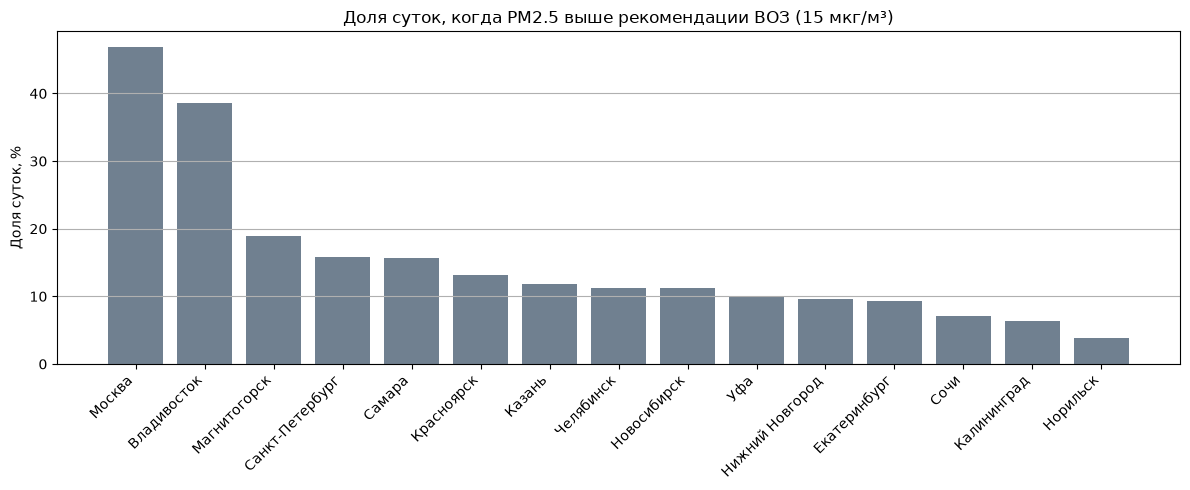

In [11]:
plt.figure(figsize=(12, 5))
plt.bar(share["city"], share["share_over"], color="slategray")
plt.title(f"Доля суток, когда PM2.5 выше рекомендации ВОЗ ({WHO_PM25_DAY} мкг/м³)")
plt.ylabel("Доля суток, %")
plt.xticks(rotation=45, ha="right")   
plt.grid(axis="y")
plt.tight_layout()
plt.savefig("chart_1_share_over_who.png", dpi=150)
plt.show()

Теперь посмотрим на структуру всех суток по индексу US AQI: сколько суток «хорошо», «умеренно» и «плохо». Сравним все 15 городов вместе и Уфу отдельно.

Индекс AQI учитывает сразу все загрязнители (не только PM2.5) и берётся по максимуму за сутки, поэтому это более строгая оценка, чем среднесуточная.
Категория «Умеренно» означает «воздух приемлемый, но для очень чувствительных людей возможен небольшой риск», так что она не равна «плохому воздуху». О плохом воздухе говорит только категория «Плохо» (AQI выше 100).

In [12]:
aqi_all = np.array(daily["aqi_us_max"])
aqi_ufa = np.array(daily.loc[daily["city"] == "Уфа", "aqi_us_max"])

def aqi_levels(aqi):
    # сколько суток: хорошо (<= 50), умеренно (51-100), плохо (> 100)
    good = np.count_nonzero(aqi <= 50)
    moderate = np.count_nonzero((aqi > 50) & (aqi <= 100))
    bad = np.count_nonzero(aqi > 100)
    return np.array([good, moderate, bad])

level_names = ["Хорошо (AQI ≤ 50)", "Умеренно (51–100)", "Плохо (> 100)"]
counts_all = aqi_levels(aqi_all)
counts_ufa = aqi_levels(aqi_ufa)

print("Все города:", dict(zip(level_names, counts_all.tolist())))
print("Уфа       :", dict(zip(level_names, counts_ufa.tolist())))

Все города: {'Хорошо (AQI ≤ 50)': 2500, 'Умеренно (51–100)': 2839, 'Плохо (> 100)': 136}
Уфа       : {'Хорошо (AQI ≤ 50)': 182, 'Умеренно (51–100)': 177, 'Плохо (> 100)': 6}


**График 2.** Круговые диаграммы: части одного целого (сутки по уровням качества воздуха).

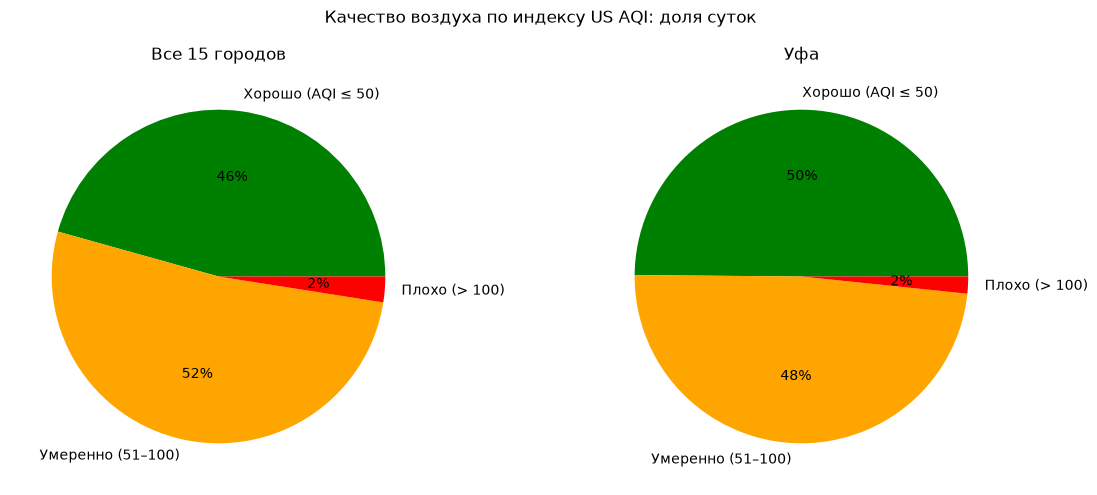

In [13]:
level_colors = ["green", "orange", "red"]
def draw_pie(axis, counts, title):
    labels = [name for name, c in zip(level_names, counts) if c > 0]
    colors = [col for col, c in zip(level_colors, counts) if c > 0]
    axis.pie(counts[counts > 0], labels=labels, autopct="%1.0f%%", colors=colors)
    axis.set_title(title)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
draw_pie(ax[0], counts_all, "Все 15 городов")
draw_pie(ax[1], counts_ufa, "Уфа")
fig.suptitle("Качество воздуха по индексу US AQI: доля суток")
plt.tight_layout()
plt.savefig("chart_2_aqi_pies.png", dpi=150)
plt.show()

In [14]:
total_days = len(daily)
days_over = daily["over_who"].sum()
print(f"Всего городо-суток: {total_days}")
print(f"Из них выше рекомендации ВОЗ: {days_over} ({days_over / total_days * 100:.1f}%)")

Всего городо-суток: 5475
Из них выше рекомендации ВОЗ: 837 (15.3%)


### Вопрос 2. Где воздух хуже всего и какое место у Уфы?

Для каждого города считаем средний и медианный PM2.5 за год и максимальные сутки.

In [15]:
city_stats = daily.groupby("city", as_index=False).agg(
    mean_pm25=("pm2_5_mean", "mean"),
    median_pm25=("pm2_5_mean", "median"),
    max_pm25=("pm2_5_mean", "max"),
)
city_stats = city_stats.sort_values("mean_pm25", ascending=False)
city_stats.round(1)

,city,mean_pm25,median_pm25,max_pm25
6,Москва,17.7,14.3,91.5
0,Владивосток,14.8,12.4,55.2
5,Магнитогорск,10.6,8.9,40.6
10,Самара,10.0,8.6,45.1
2,Казань,9.4,7.2,71.2
4,Красноярск,9.4,7.8,59.8
11,Санкт-Петербург,9.3,7.7,42.1
14,Челябинск,8.8,7.5,32.7
7,Нижний Новгород,8.8,7.4,37.5
13,Уфа,8.8,7.3,45.7


**График 3.** Средний PM2.5 по городам.

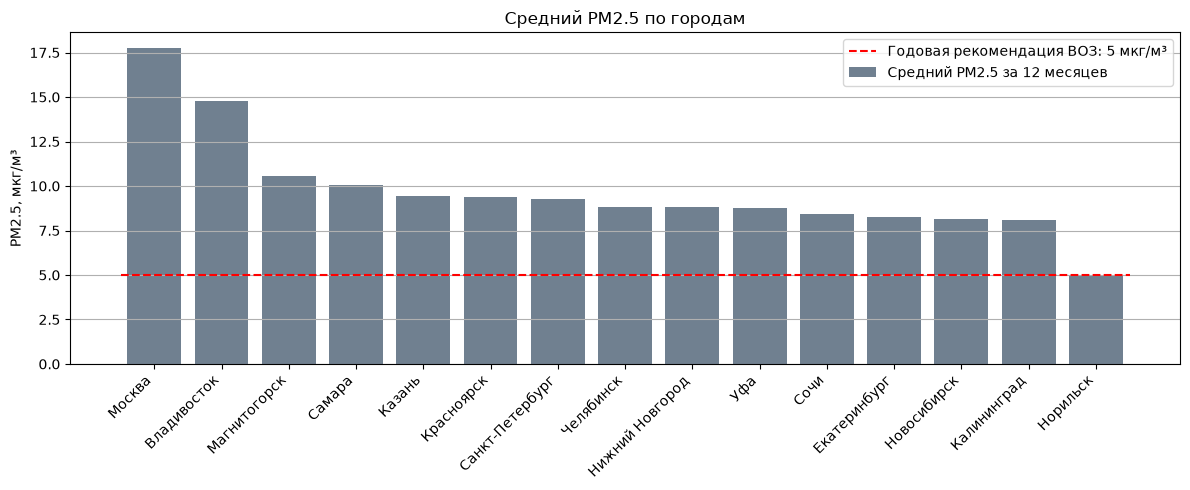

In [16]:
plt.figure(figsize=(12, 5))
plt.bar(city_stats["city"], city_stats["mean_pm25"], label="Средний PM2.5 за 12 месяцев", color="slategray")
plt.plot([-0.5, len(city_stats) - 0.5], [WHO_PM25_YEAR, WHO_PM25_YEAR],
         linestyle="--", color="red", label=f"Годовая рекомендация ВОЗ: {WHO_PM25_YEAR} мкг/м³")
plt.title("Средний PM2.5 по городам")
plt.ylabel("PM2.5, мкг/м³")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.legend()
plt.tight_layout()
plt.savefig("chart_3_mean_by_city.png", dpi=150)
plt.show()

In [17]:
ranking = list(city_stats["city"])
ufa_rank = ranking.index("Уфа") + 1
print(f"Уфа: {ufa_rank}-е место из {len(ranking)} по среднему PM2.5")

Уфа: 10-е место из 15 по среднему PM2.5


### Вопрос 3. Как воздух меняется по сезонам и бывают ли резкие всплески?

Сначала считаем средний PM2.5 по месяцам. Группировка по `year` и `month` даёт месяцы в хронологическом порядке (октябрь 2025 → сентябрь 2026).
Для линий выберем Уфу, два самых загрязнённых города и самый чистый.

Сезоны считаем по месяцам: зима — декабрь–февраль, весна — март–май, лето — июнь–август, осень — сентябрь–ноябрь (в нашем периоде это сентябрь 2026 и октябрь–ноябрь 2025).

Среднее чувствительно к редким очень высоким значениям, поэтому рядом со средним считаем **медиану** (она от редких пиков почти не зависит).

In [18]:
monthly = daily.groupby(["city", "year", "month"], as_index=False).agg(pm25=("pm2_5_mean", "mean"))

worst_two = ranking[:2]
cleanest = ranking[-1:]
show = ["Уфа"] + [c for c in worst_two + cleanest if c != "Уфа"]
print("Города на графике:", show)

Города на графике: ['Уфа', 'Москва', 'Владивосток', 'Норильск']


In [19]:
month_names = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
season_order = ["зима", "весна", "лето", "осень"]

season_mean = np.array([daily.loc[daily["season"] == s, "pm2_5_mean"].mean() for s in season_order])
season_median = np.array([daily.loc[daily["season"] == s, "pm2_5_mean"].median() for s in season_order])
ufa_season = np.array([
    daily.loc[(daily["city"] == "Уфа") & (daily["season"] == s), "pm2_5_mean"].mean()
    for s in season_order
])
print("Сезоны              :", season_order)
print("Среднее, 15 городов :", season_mean.round(1))
print("Медиана, 15 городов :", season_median.round(1))
print("Среднее, Уфа        :", ufa_season.round(1))

Сезоны              : ['зима', 'весна', 'лето', 'осень']
Среднее, 15 городов : [ 9.2 11.7  9.7  8.1]
Медиана, 15 городов : [6.9 9.  8.5 6.9]
Среднее, Уфа        : [ 9.  10.4  8.3  7.4]


**График 4.** Слева — динамика по месяцам . Справа — сезоны: столбцы показывают среднее по 15 городам.

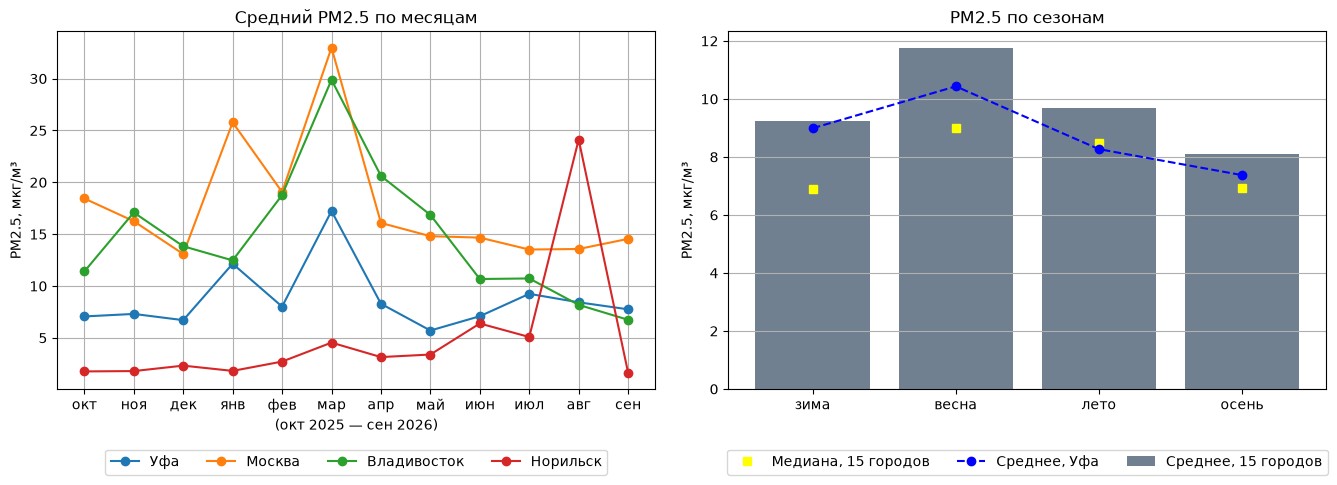

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for c in show:
    part = monthly.loc[monthly["city"] == c]
    labels = [month_names[m - 1] for m in part["month"]]
    ax[0].plot(labels, part["pm25"], marker="o", label=c)
ax[0].set_title("Средний PM2.5 по месяцам")
ax[0].set_xlabel("(окт 2025 — сен 2026)")
ax[0].set_ylabel("PM2.5, мкг/м³")
ax[0].grid()
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)  

ax[1].bar(season_order, season_mean, label="Среднее, 15 городов", color="slategray")
ax[1].plot(season_order, season_median, marker="s", linestyle="None", color="yellow", label="Медиана, 15 городов")
ax[1].plot(season_order, ufa_season, marker="o", linestyle="--", color="blue", label="Среднее, Уфа")
ax[1].set_title("PM2.5 по сезонам")
ax[1].set_ylabel("PM2.5, мкг/м³")
ax[1].grid(axis="y")
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

plt.tight_layout()
plt.savefig("chart_4_seasons.png", dpi=150, bbox_inches="tight")
plt.show()

#### Всплески: насколько на сезонные средние влияют отдельные эпизоды

Если среднее заметно выше медианы, значит, картину тянут вверх редкие очень плохие сутки. Проверим это и найдём самые тяжёлые сутки.

In [21]:
mean_all = daily["pm2_5_mean"].mean()
median_all = daily["pm2_5_mean"].median()
max_all = daily["pm2_5_mean"].max()
n_peak = int(daily["peak"].sum())

print(f"Среднее PM2.5 по всем суткам: {mean_all:.1f} мкг/м³")
print(f"Медиана                     : {median_all:.1f} мкг/м³")
print(f"Максимум за сутки           : {max_all:.1f} мкг/м³")
print(f"Суток с PM2.5 выше {PEAK_PM25} мкг/м³: {n_peak} ({n_peak / len(daily) * 100:.1f}% всех городо-суток)")

Среднее PM2.5 по всем суткам: 9.7 мкг/м³
Медиана                     : 7.9 мкг/м³
Максимум за сутки           : 99.7 мкг/м³
Суток с PM2.5 выше 35 мкг/м³: 87 (1.6% всех городо-суток)


Десять самых тяжёлых городо-суток:

In [22]:
daily.sort_values("pm2_5_mean", ascending=False)[["city", "date", "pm2_5_mean", "wind_ms_mean"]].head(10)

,city,date,pm2_5_mean,wind_ms_mean
3613,Норильск,2026-08-25,99.65,3.25
3617,Норильск,2026-08-29,92.29,3.87
2306,Москва,2026-01-25,91.46,1.19
3614,Норильск,2026-08-26,90.25,6.64
2305,Москва,2026-01-24,89.84,0.57
3612,Норильск,2026-08-24,79.19,1.09
3615,Норильск,2026-08-27,72.23,4.22
3184,Новосибирск,2026-06-22,71.35,2.84
899,Казань,2026-03-19,71.16,1.14
2297,Москва,2026-01-16,69.20,1.14


Сколько городо-суток с сильным всплеском приходится на каждый месяц:

In [23]:
peaks_by_month = daily.groupby(["year", "month"], as_index=False).agg(peak_days=("peak", "sum"))
peaks_by_month

,year,month,peak_days
0,2025,10,3
1,2025,11,2
2,2025,12,2
3,2026,1,13
4,2026,2,5
5,2026,3,41
6,2026,4,6
7,2026,5,1
8,2026,6,3
9,2026,7,2


**График 5.** Столбчатая диаграмма: в какие месяцы чаще всего случаются сильные всплески (по всем 15 городам вместе).

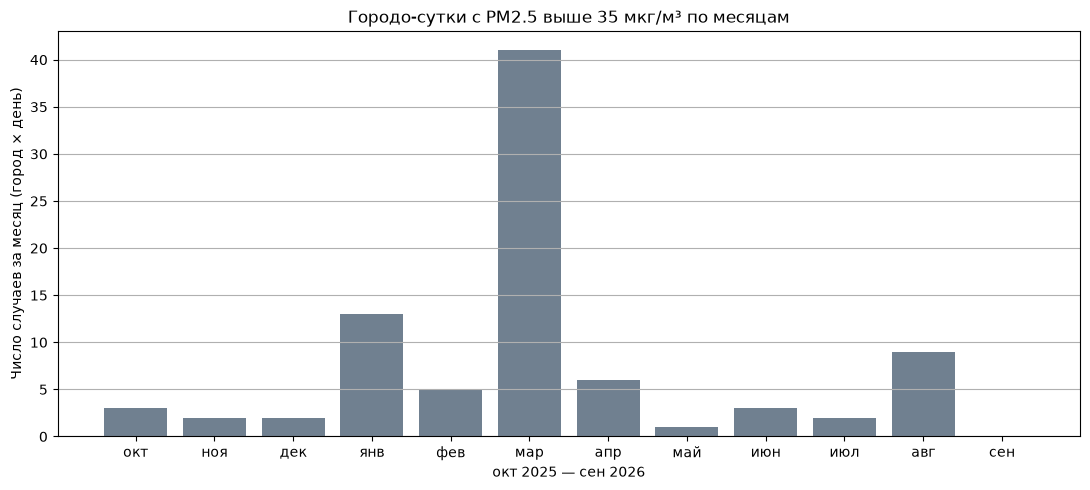

In [24]:
peak_labels = [month_names[m - 1] for m in peaks_by_month["month"]]

plt.figure(figsize=(11, 5))
plt.bar(peak_labels, peaks_by_month["peak_days"], color="slategray")
plt.title(f"Городо-сутки с PM2.5 выше {PEAK_PM25} мкг/м³ по месяцам")
plt.xlabel("окт 2025 — сен 2026")
plt.ylabel("Число случаев за месяц (город × день)")
plt.grid(axis="y")
plt.tight_layout()
plt.savefig("chart_5_peaks_by_month.png", dpi=150)
plt.show()

Если всплески в разных городах происходят в одни и те же даты, это похоже на общий эпизод (например, дым, пыль или особенность модели), а не на местную проблему. Посмотрим даты, когда одновременно в пике было больше всего городов:

In [25]:
by_date = daily.groupby("date", as_index=False).agg(cities_in_peak=("peak", "sum"))
by_date = by_date.sort_values("cities_in_peak", ascending=False)
by_date.head(5)

,date,cities_in_peak
175,2026-03-25,4
169,2026-03-19,4
168,2026-03-18,4
179,2026-03-29,3
167,2026-03-17,3


### Вопрос 4. Есть ли устойчивый суточный ритм?

Для каждого города берём 8760 почасовых значений PM2.5 и превращаем их в матрицу «365 суток × 24 часа».
Среднее по оси суток даёт типичный «профиль» одного дня.

Профили складываем в общую матрицу. Чтобы сравнивать города с разным уровнем загрязнения, делим каждый профиль на среднегодовой уровень этого города: значение 1 означает «как обычно для этого города».

In [26]:
profiles = np.vstack([
    np.array(hourly.loc[hourly["city"] == c, "pm2_5"]).reshape(-1, 24).mean(axis=0)
    for c in city_names
])
print("Матрица профилей (города × часы):", profiles.shape)

rel_profiles = profiles / profiles.mean(axis=1, keepdims=True)
rel_avg = rel_profiles.mean(axis=0)

Матрица профилей (города × часы): (15, 24)


**Проверка профилей.** У настоящего суточного цикла (дороги, отопление, проветривание атмосферы) значения меняются плавно. Если на профилях есть резкие скачки,
это повод усомниться в данных. Для каждого города найдём час, в который профиль меняется резче всего (разность соседних часов делаем срезами), и переведём этот час во время UTC:
если города из разных часовых поясов имеют скачок в один и тот же момент по UTC, то причина не в жизни города, а в том, как модель выдаёт данные.

In [27]:
offset = np.array([cities.loc[cities["city"] == c, "utc_offset_hours"].iloc[0] for c in city_names])

jump = np.abs(rel_profiles[:, 1:] - rel_profiles[:, :-1])   # изменение за один час, форма (15, 23)
jump_local = np.argmax(jump, axis=1) + 1                    # местный час, в который профиль меняется резче всего
jump_utc = ((jump_local - offset) % 24).astype(int)         # тот же момент по времени UTC

jump_table = pd.DataFrame({
    "city": city_names,
    "скачок в местный час": jump_local,
    "тот же момент по UTC": jump_utc,
    "размер скачка, % от обычного уровня": (jump.max(axis=1) * 100).round(0),
})
jump_table

,city,скачок в местный час,тот же момент по UTC,"размер скачка, % от обычного уровня"
0,Владивосток,22,12,18.0
1,Екатеринбург,17,12,28.0
2,Казань,15,12,19.0
3,Калининград,14,12,9.0
4,Красноярск,19,12,26.0
5,Магнитогорск,17,12,17.0
6,Москва,15,12,13.0
7,Нижний Новгород,15,12,19.0
8,Новосибирск,19,12,27.0
9,Норильск,19,12,26.0


In [28]:
utc_hours, utc_counts = np.unique(jump_utc, return_counts=True)
top_utc_hour = int(utc_hours[np.argmax(utc_counts)])
top_utc_count = int(utc_counts.max())
print(f"Самый резкий скачок профиля приходится на {top_utc_hour}:00 по UTC у {top_utc_count} городов из {len(city_names)}")

Самый резкий скачок профиля приходится на 12:00 по UTC у 14 городов из 15


**График 6.** Слева — суточные профили выбранных городов , справа — в какой час по UTC у города самый резкий скачок профиля.

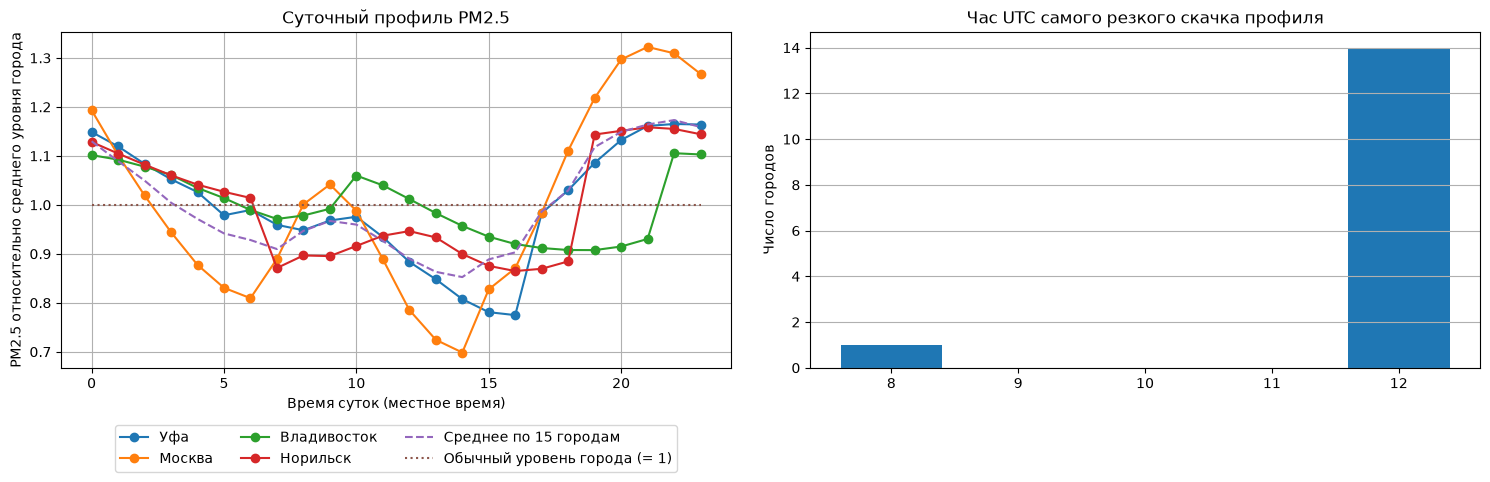

In [29]:
hours = np.arange(24)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for c in show:
    ax[0].plot(hours, rel_profiles[city_names.index(c)], marker="o", label=c)
ax[0].plot(hours, rel_avg, linestyle="--", label="Среднее по 15 городам")
ax[0].plot([0, 23], [1, 1], linestyle=":", label="Обычный уровень города (= 1)")
ax[0].set_title("Суточный профиль PM2.5")
ax[0].set_xlabel("Время суток (местное время)")
ax[0].set_ylabel("PM2.5 относительно среднего уровня города")
ax[0].grid()
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

ax[1].bar(utc_hours, utc_counts)
ax[1].set_title("Час UTC самого резкого скачка профиля")
ax[1].set_ylabel("Число городов")
ax[1].grid(axis="y")

plt.tight_layout()
plt.savefig("chart_6_daily_cycle.png", dpi=150, bbox_inches="tight")
plt.show()

### Вопрос 5. Связан ли PM2.5 с погодой?

Города сильно различаются по уровню PM2.5 и по климату (Сочи и Норильск), поэтому сравнивать «сырые» значения разных городов нельзя.
Вместо этого для каждого города считаем **отклонение от его собственного среднего**: матрица `города × сутки`, из каждой строки вычитаем её среднее.

Силу связи измеряем коэффициентом корреляции, который считаем по формуле: нормализуем оба массива (z-оценка) и берём среднее от их произведения.

In [30]:
n_cities = len(city_names)

pm = np.array(daily["pm2_5_mean"]).reshape(n_cities, -1)
wind = np.array(daily["wind_ms_mean"]).reshape(n_cities, -1)
temp = np.array(daily["temp_c_mean"]).reshape(n_cities, -1)

pm_dev = pm - pm.mean(axis=1, keepdims=True)
wind_dev = wind - wind.mean(axis=1, keepdims=True)
temp_dev = temp - temp.mean(axis=1, keepdims=True)

def correlation(a, b):
    za = (a - a.mean()) / a.std()
    zb = (b - b.mean()) / b.std()
    return (za * zb).mean()

r_wind = correlation(pm_dev.reshape(-1), wind_dev.reshape(-1))
r_temp = correlation(pm_dev.reshape(-1), temp_dev.reshape(-1))
print("Матрица PM2.5 (города × сутки):", pm.shape)
print(f"Корреляция PM2.5 и ветра       : {r_wind:.2f}")
print(f"Корреляция PM2.5 и температуры : {r_temp:.2f}")

Матрица PM2.5 (города × сутки): (15, 365)
Корреляция PM2.5 и ветра       : -0.34
Корреляция PM2.5 и температуры : -0.05


Коэффициент показывает среднюю связь, а на графике видно, что главная проблема — редкие всплески. Проверим отдельно: при каком ветре случаются сильные всплески?
Сравним долю суток со слабым ветром (слабее обычного для города) среди суток-всплесков и среди всех суток.

In [31]:
pm_flat = pm.reshape(-1)
wind_dev_flat = wind_dev.reshape(-1)

peak_mask = pm_flat > PEAK_PM25
n_peak_check = np.count_nonzero(peak_mask)
all_low_wind = np.count_nonzero(wind_dev_flat < 0) / wind_dev_flat.size * 100

if n_peak_check > 0:
    peaks_low_wind = np.count_nonzero(peak_mask & (wind_dev_flat < 0)) / n_peak_check * 100
    print(f"Среди суток со всплеском (PM2.5 > {PEAK_PM25}) ветер слабее обычного был в {peaks_low_wind:.0f}% случаев")
    print(f"Среди всех суток ветер слабее обычного был в {all_low_wind:.0f}% случаев")
else:
    peaks_low_wind = None
    print("Сильных всплесков в данных нет")

Среди суток со всплеском (PM2.5 > 35) ветер слабее обычного был в 89% случаев
Среди всех суток ветер слабее обычного был в 55% случаев


**График 7.** Диаграммы рассеяния: каждая точка — один город в одни сутки.

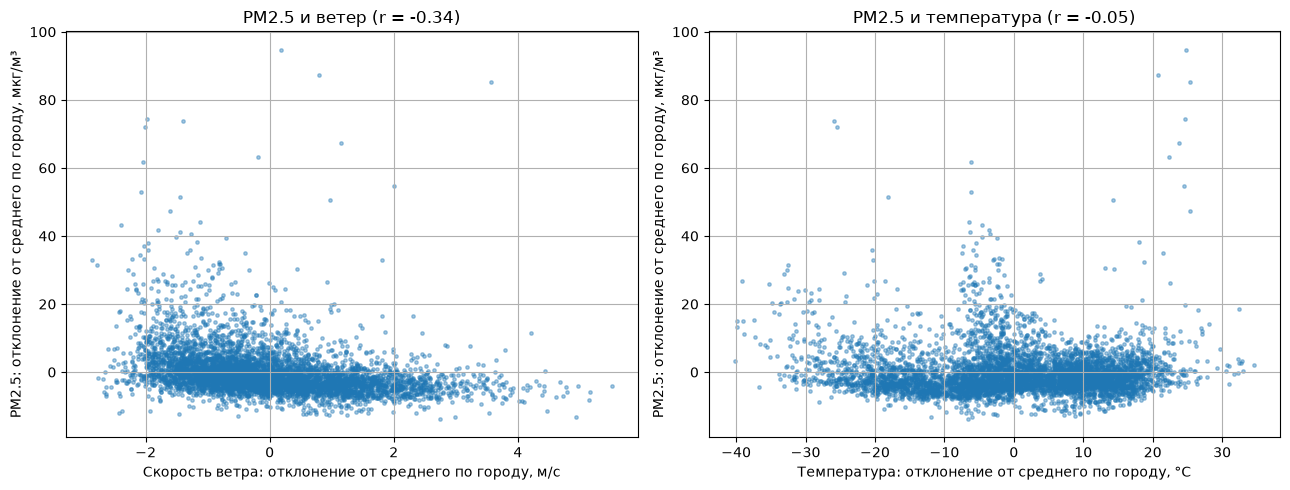

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(wind_dev.reshape(-1), pm_dev.reshape(-1), s=6, alpha=0.4)
ax[0].set_title(f"PM2.5 и ветер (r = {r_wind:.2f})")
ax[0].set_xlabel("Скорость ветра: отклонение от среднего по городу, м/с")
ax[0].set_ylabel("PM2.5: отклонение от среднего по городу, мкг/м³")
ax[0].grid()

ax[1].scatter(temp_dev.reshape(-1), pm_dev.reshape(-1), s=6, alpha=0.4)
ax[1].set_title(f"PM2.5 и температура (r = {r_temp:.2f})")
ax[1].set_xlabel("Температура: отклонение от среднего по городу, °C")
ax[1].set_ylabel("PM2.5: отклонение от среднего по городу, мкг/м³")
ax[1].grid()

plt.tight_layout()
plt.savefig("chart_7_weather.png", dpi=150)
plt.show()

### Итоговая таблица по городам

Собираем всё в один отчёт и сохраняем в CSV.

In [33]:
city_stats["p95_pm25"] = [
    np.percentile(np.array(daily.loc[daily["city"] == c, "pm2_5_mean"]), 95)
    for c in city_stats["city"]
]
city_stats["share_over_who"] = [
    share.loc[share["city"] == c, "share_over"].iloc[0]
    for c in city_stats["city"]
]

city_stats.round(1).to_csv("analysis_summary.csv", index=False)
city_stats.round(1)

,city,mean_pm25,median_pm25,max_pm25,p95_pm25,share_over_who
6,Москва,17.7,14.3,91.5,40.6,46.8
0,Владивосток,14.8,12.4,55.2,32.8,38.6
5,Магнитогорск,10.6,8.9,40.6,24.6,18.9
10,Самара,10.0,8.6,45.1,21.0,15.6
2,Казань,9.4,7.2,71.2,24.2,11.8
4,Красноярск,9.4,7.8,59.8,22.6,13.2
11,Санкт-Петербург,9.3,7.7,42.1,20.4,15.9
14,Челябинск,8.8,7.5,32.7,19.5,11.2
7,Нижний Новгород,8.8,7.4,37.5,22.7,9.6
13,Уфа,8.8,7.3,45.7,20.3,9.9


### Расчётные числа для выводов

Ячейка ниже собирает формулировки из расчётов выше.(Итоговые выводы своими словами — в следующем разделе)

In [34]:
# ----- числа -----
share_worst_city, share_worst = share["city"].iloc[0], share["share_over"].iloc[0]
share_best_city, share_best = share["city"].iloc[-1], share["share_over"].iloc[-1]
share_total = days_over / total_days * 100

worst_city, worst_mean = ranking[0], city_stats["mean_pm25"].iloc[0]
best_city, best_mean = ranking[-1], city_stats["mean_pm25"].iloc[-1]
ratio = worst_mean / best_mean
n_above_year = int((city_stats["mean_pm25"] > WHO_PM25_YEAR).sum())

ufa_mean = city_stats.loc[city_stats["city"] == "Уфа", "mean_pm25"].iloc[0]
ufa_share = share.loc[share["city"] == "Уфа", "share_over"].iloc[0]
ufa_close = [c for c, m in zip(city_stats["city"], city_stats["mean_pm25"]) if c != "Уфа" and abs(m - ufa_mean) < 0.3]
bad_share = counts_all[2] / counts_all.sum() * 100

worst_season = season_order[int(np.argmax(season_mean))]
best_season = season_order[int(np.argmin(season_mean))]
worst_season_med = season_order[int(np.argmax(season_median))]
best_season_med = season_order[int(np.argmin(season_median))]
season_gap = (season_mean.max() - season_mean.min()) / season_mean.mean() * 100
ufa_months = monthly.loc[monthly["city"] == "Уфа"].sort_values("pm25", ascending=False)
ufa_worst_month = month_names[int(ufa_months["month"].iloc[0]) - 1]
ufa_worst_month_value = ufa_months["pm25"].iloc[0]

def strength(r):
    a = abs(r)
    if a < 0.2:
        return "очень слабая"
    elif a < 0.4:
        return "слабая"
    elif a < 0.6:
        return "умеренная"
    return "сильная"

def sign(r):
    return "отрицательная" if r < 0 else "положительная"

# ----- вывод -----
print("РАСЧЁТНЫЕ ЧИСЛА\n")
print(f"1. Масштаб. В {share_total:.1f}% городо-суток ({days_over} из {total_days}) среднесуточный PM2.5 был выше рекомендации ВОЗ ({WHO_PM25_DAY} мкг/м³).")
print(f"   Чаще всего — в г. {share_worst_city} ({share_worst:.0f}% суток), реже всего — в г. {share_best_city} ({share_best:.0f}%).")
print(f"   Доля суток с плохим воздухом (US AQI > 100): {bad_share:.1f}%.")
print()
print(f"2. География (по модели CAMS). Средний PM2.5 за год — от {best_mean:.1f} мкг/м³ ({best_city}) до {worst_mean:.1f} мкг/м³ ({worst_city}), разница в {ratio:.1f} раза.")
print(f"   Годовую рекомендацию ВОЗ ({WHO_PM25_YEAR} мкг/м³) превышают {n_above_year} из {len(ranking)} городов.")
print(f"   Уфа: {ufa_rank}-е место из {len(ranking)} (1 — самый загрязнённый), среднее {ufa_mean:.1f} мкг/м³, {ufa_share:.0f}% суток выше рекомендации ВОЗ.")
if len(ufa_close) > 0:
    print(f"   Почти такой же уровень (в пределах 0,3 мкг/м³) у: {', '.join(ufa_close)}, поэтому точное место Уфы в рейтинге условно: она в середине списка.")
if best_city == "Норильск":
    print("   Норильск оказался самым «чистым» по модели, но это не значит, что воздух там чистый — модель сглаживает промышленные выбросы (см. «Ограничения»).")
print()
print(f"3. Сезонность и всплески. По среднему хуже всего сезон «{worst_season}» ({season_mean.max():.1f} мкг/м³), лучше всего — «{best_season}» ({season_mean.min():.1f}); разница {season_gap:.0f}% от среднего.")
print(f"   По медиане (она не зависит от редких пиков): хуже всего «{worst_season_med}» ({season_median.max():.1f}), лучше всего «{best_season_med}» ({season_median.min():.1f}).")
if worst_season != worst_season_med:
    print("   Порядок сезонов по среднему и по медиане разный: на сезонные средние сильно влияют отдельные эпизоды, поэтому уверенного вывода «в такой-то сезон всегда хуже» сделать нельзя.")
else:
    print("   Худший сезон по среднему и по медиане совпадает, значит, сезонное различие не объясняется только редкими эпизодами (но за один год о тренде говорить рано).")
print(f"   Среднее по всем суткам ({mean_all:.1f}) выше медианы ({median_all:.1f}), максимум за сутки — {max_all:.1f} мкг/м³: картину поднимают редкие сильные всплески.")
if n_peak > 0:
    top_row = peaks_by_month.sort_values("peak_days", ascending=False).iloc[0]
    top_month_name = month_names[int(top_row["month"]) - 1]
    top_month_share = top_row["peak_days"] / n_peak * 100
    max_cities = int(by_date["cities_in_peak"].iloc[0])
    max_date = by_date["date"].iloc[0]
    print(f"   Суток с PM2.5 выше {PEAK_PM25} мкг/м³: {n_peak} ({n_peak / total_days * 100:.1f}%); больше всего — в месяце «{top_month_name}» ({top_month_share:.0f}% всех таких суток).")
    print(f"   Больше всего городов одновременно в пике: {max_cities} (дата {max_date}).")
    if max_cities >= 4:
        print("   Несколько городов в пике в одну дату — похоже на общий эпизод (дым, пыль или особенность модели); причину по этим данным определить нельзя.")
print(f"   В Уфе самый загрязнённый месяц — {ufa_worst_month} ({ufa_worst_month_value:.1f} мкг/м³).")
print()
print(f"4. Суточный ритм. Самый частый час UTC, на который приходится резкий скачок профиля, — {top_utc_hour}:00: так у {top_utc_count} городов из {len(city_names)}.")
if top_utc_count >= len(city_names) / 2:
    print("   Это похоже на особенность выдачи модели, а не на реальный суточный цикл, поэтому надёжно определить «лучшее время суток» по этим данным нельзя.")
    print("   В проекте подсказку «когда выйти на улицу» лучше строить по почасовому прогнозу, а не по средним значениям.")
else:
    print("   Скачки приходятся на разное время, артефакт выдачи не подтверждён; ритм можно использовать, но осторожно (данные модельные).")
print()
print(f"5. Погода. Связь PM2.5 с ветром: r = {r_wind:.2f} ({strength(r_wind)}, {sign(r_wind)}); с температурой: r = {r_temp:.2f} ({strength(r_temp)}, {sign(r_temp)}).")
if r_wind <= -0.2:
    print("   При более сильном ветре PM2.5 в среднем ниже (согласуется с тем, что ветер рассеивает частицы).")
elif r_wind >= 0.2:
    print("   При более сильном ветре PM2.5 в среднем выше.")
else:
    print("   Связь PM2.5 с ветром слабая.")
if peaks_low_wind is not None:
    print(f"   Сильные всплески случаются при слабом ветре в {peaks_low_wind:.0f}% случаев (среди всех суток — {all_low_wind:.0f}%).")
print("   Корреляция показывает связь, но не доказывает причину.")

РАСЧЁТНЫЕ ЧИСЛА

1. Масштаб. В 15.3% городо-суток (837 из 5475) среднесуточный PM2.5 был выше рекомендации ВОЗ (15 мкг/м³).
   Чаще всего — в г. Москва (47% суток), реже всего — в г. Норильск (4%).
   Доля суток с плохим воздухом (US AQI > 100): 2.5%.

2. География (по модели CAMS). Средний PM2.5 за год — от 4.9 мкг/м³ (Норильск) до 17.7 мкг/м³ (Москва), разница в 3.6 раза.
   Годовую рекомендацию ВОЗ (5 мкг/м³) превышают 14 из 15 городов.
   Уфа: 10-е место из 15 (1 — самый загрязнённый), среднее 8.8 мкг/м³, 10% суток выше рекомендации ВОЗ.
   Почти такой же уровень (в пределах 0,3 мкг/м³) у: Челябинск, Нижний Новгород, поэтому точное место Уфы в рейтинге условно: она в середине списка.
   Норильск оказался самым «чистым» по модели, но это не значит, что воздух там чистый — модель сглаживает промышленные выбросы (см. «Ограничения»).

3. Сезонность и всплески. По среднему хуже всего сезон «весна» (11.7 мкг/м³), лучше всего — «осень» (8.1); разница 37% от среднего.
   По медиане (она не

## Выводы и обоснование проекта


**1. Проблема существует и она не единичная.** За 12 месяцев в 15 городах среднесуточный PM2.5 превысил рекомендацию ВОЗ (15 мкг/м³) в 837 из 5475 городо-суток, это **15,3%**.
По индексу US AQI 2,5% суток попали в категорию «плохо» (выше 100).

**2. Города заметно различаются.** По модели CAMS средний PM2.5 за год — от 4,9 мкг/м³ (Норильск) до 17,7 мкг/м³ (Москва).
В Москве превышение суточной рекомендации случается в 47% суток, во Владивостоке в 39%, в остальных городах — от 4% до 19%.
Годовую рекомендацию ВОЗ (5 мкг/м³) превышают 14 из 15 городов.
Уфа находится в середине рейтинга: 8,8 мкг/м³ (10-е место из 15, столько же у Челябинска и Нижнего Новгорода), 10% суток выше суточной рекомендации (36 суток), 6 суток с индексом AQI выше 100.

**3. Плохой воздух приходит эпизодами.** Среднее PM2.5 по всем суткам (9,7 мкг/м³) выше медианы (7,9), а максимум за сутки — 99,65 мкг/м³ (Норильск, 25 августа 2026).
Сильные всплески (PM2.5 выше 35 мкг/м³) редки: 87 городо-суток из 5475 (1,6%). Но они собраны «кучками»:
- **март 2026** — 41 из 87 всплесков (47%); 17–29 марта в пике одновременно бывали до 4 городов, то есть это похоже на общий эпизод, причину которого по нашим данным определить нельзя;
- **январь** — 13 городо-суток, в том числе самые тяжёлые сутки Москвы (24–25 января);
- **конец августа** — Норильск: 5 из 7 самых тяжёлых городо-суток за год.

**Сезонность.** Весна хуже всего и по среднему (11,7 мкг/м³ против 8,1 осенью), и по медиане (9,0), так что весна этого года действительно была хуже, но разницу заметно усиливает мартовский эпизод.
У зимы медиана самая низкая (6,9, как у осени), а среднее выше (9,2): зиму «поднимают» редкие всплески, в основном январские. Данные охватывают один год, поэтому считать это устойчивой закономерностью нельзя.

**4. Ветер связан с PM2.5 слабо в среднем, но заметно для всплесков.** Корреляция со скоростью ветра слабая отрицательная (r = −0,34): при более сильном ветре PM2.5 в среднем ниже.
При этом 89% сильных всплесков случились при ветре слабее обычного для города, хотя в целом такой ветер бывает в 55% суток. С температурой связи практически нет (r = −0,05). Корреляция не доказывает причину.

**5. Суточный ритм по этим данным надёжно оценить нельзя.** У 14 из 15 городов самый резкий скачок суточного профиля приходится на 12:00 по времени UTC, хотя по местному времени это разные часы (от 14:00 в Калининграде до 22:00 во Владивостоке), а размер скачка — от 9% до 28% от обычного уровня (график 6).
Это похоже на особенность выдачи модели, а не на реальный суточный цикл. Поэтому подсказку «лучшее время для прогулки» в проекте нужно строить по почасовому прогнозу, а не по средним за год.

#### Почему проект «Дышим чисто» нужен

- В 15% суток воздух выше рекомендации ВОЗ, а уровень PM2.5 трудно оценить на глаз, поэтому человеку нужен понятный и доступный показатель.
- Города сильно отличаются (в Москве превышения в 47% суток, в Норильске в 4%), поэтому нужен показ для своего города и возможность сравнить города между собой.
- Ухудшения приходят эпизодами в разное время года и в разных городах (январь в Москве, март сразу в нескольких городах, август в Норильске). Заметить такой эпизод заранее трудно, поэтому полезны оповещение при превышении порога и история замеров.
- Уфа не худший город, но и здесь за год было 36 суток выше суточной рекомендации ВОЗ, а в марте среднее PM2.5 было почти вдвое выше годового (17,2 против 8,8 мкг/м³).
- Подсказки по времени надёжнее строить по свежему прогнозу, а не по историческому среднему. Это определяет архитектуру проекта: сайт берёт данные из API в реальном времени.

#### Как выводы связаны с функциями сайта

| Вывод анализа | Функции сайта "Дышим чисто"(предполагаемые) |
|---|---|
| Города заметно отличаются по качеству воздуха | карточка города с цветной индикацией и страница сравнения городов |
| Всплески эпизодические, в разное время года и в разных городах | оповещение при превышении порога и история замеров |
| Сильные всплески почти всегда при слабом ветре (89%) | рядом с карточкой показываем ветер и температуру как пояснение |
| Суточный профиль по средним данным ненадёжен | подсказка «лучшее время для прогулки» по почасовому прогнозу API |

### Ограничения анализа

- **Данные модельные.** Это оценки модели CAMS (Copernicus) на крупной сетке (десятки километров), а не показания датчиков. Точечные источники (заводы, ТЭЦ, дороги) сглаживаются, поэтому абсолютные значения могут отличаться от местных датчиков. Например, Норильск оказался самым «чистым» городом по модели, но из этого нельзя заключить, что воздух там действительно чистый. Это ограничение метода.
- **Скачки в суточных профилях.** Почасовые данные модели содержат резкие скачки в один и тот же момент по UTC, поэтому средний суточный ритм использовать как доказательство нельзя.
- **Причины всплесков не установлены.** Мартовский эпизод в нескольких далёких городах и августовский в Норильске могут быть дымом, пылью или особенностью модели. Фиксируется сам факт всплесков, но не их причина.
- **Один год.** Видны особенности этих 12 месяцев, а не многолетнюю закономерность; несколько сильных всплесков заметно влияют на сезонные средние.
- **ВОЗ — это рекомендации.** Они строже российских нормативов, поэтому «выше рекомендации ВОЗ» не означает «нарушение закона».
- **Корреляция не равна причине.** Связь PM2.5 с ветром или температурой - наблюдение, а не доказательство.
- **Города учитываются с одинаковым весом.** Средние по 15 городам не учитывают численность населения.